# 10 · ¿Cobrar más causa más mora? Inferencia causal de la tasa

El motor de la sesión 9 supone que la PD **no reacciona a la tasa**. Pero los datos muestran que los préstamos más caros caen más. ¿La tasa **causa** la mora (cuota más pesada, selección adversa) o Lending Club simplemente le cobra más a quien ya es más riesgoso? Si es lo primero, la tasa sugerida subestima el riesgo (decisión 014).

**Experimento natural:** Lending Club fijaba la tasa por subgrado con tablas que cambiaba en meses distintos para cada subgrado. Si esos cambios son "como aleatorios", comparar el mismo subgrado antes y después de un cambio identifica el efecto causal.

| Método | Qué compara | Supuesto clave |
|---|---|---|
| Efectos fijos de dos vías | El mismo subgrado en meses con tasas distintas, contra los subgrados que no cambiaron ese mes | Tendencias paralelas |
| DML con LightGBM | Residuo de la mora contra residuo de la tasa, tras predecir ambas con el perfil, el subgrado y el mes | No hay confusores fuera de X |
| Placebo | La tasa del **mes siguiente** contra la mora de hoy | Debe dar ≈ 0 |

Todo se estima con el entrenamiento (sep-2012 a dic-2014); el backtest usa jul–dic 2015. Código: `src/credit_lab/causal.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from credit_lab import causal
from credit_lab.features import LOGISTICA, derivar
from credit_lab.motor import Motor, tasa_minima_lote, ROI_OBJETIVO
from credit_lab.poblacion import cargar_poblacion
from credit_lab.prepago import rendimiento
from credit_lab.transformadores import preprocesador

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

df = causal.preparar(cargar_poblacion())
tr = df[df["muestra"].eq("train")].reset_index(drop=True)
tr["tasa_sig"] = causal.tasa_siguiente(tr)
d = tr.dropna(subset=["tasa_sig"]).reset_index(drop=True)   # el placebo necesita el mes siguiente
print(f"Entrenamiento: {len(tr):,} préstamos · con mes siguiente disponible: {len(d):,}")

Entrenamiento: 283,253 préstamos · con mes siguiente disponible: 276,342


## 1. El experimento natural: la tasa del mismo subgrado cambia con el mes

Dentro de cada subgrado, el mes explica el 93.1% de la variación de la tasa


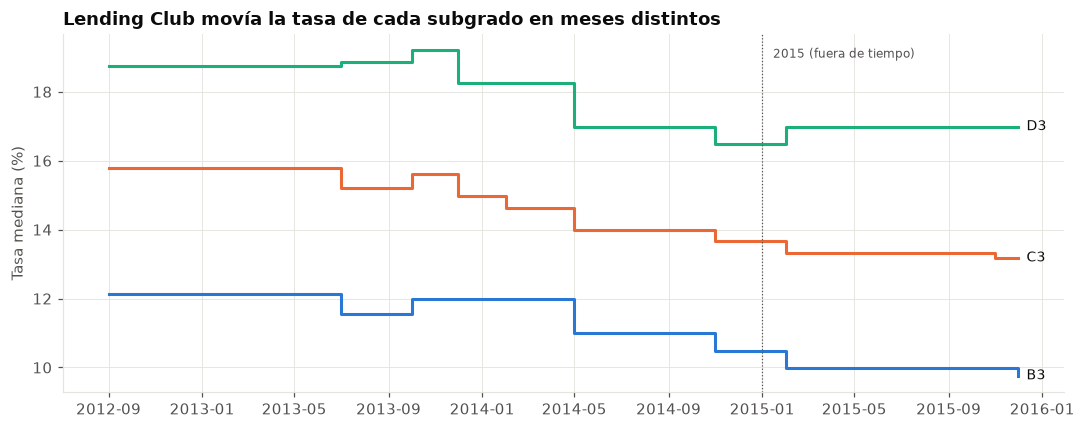

In [2]:
dentro_sg = d["int_rate"] - d.groupby("sub_grade")["int_rate"].transform("mean")
dentro_celda = d["int_rate"] - d.groupby(["sub_grade", "mes"])["int_rate"].transform("mean")
print(f"Dentro de cada subgrado, el mes explica el {1 - dentro_celda.var() / dentro_sg.var():.1%} de la variación de la tasa")

tabla = df.groupby(["sub_grade", "issue_d"])["int_rate"].median().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for sg, color in [("B3", AZUL), ("C3", NARANJA), ("D3", VERDE)]:
    serie = tabla[sg].dropna()
    ax.step(serie.index, serie.values, where="post", color=color, linewidth=2)
    ax.text(serie.index[-1], serie.values[-1], f"  {sg}", color=TINTA, va="center", fontsize=9)
ax.axvline(pd.Timestamp("2015-01-01"), color=TINTA_2, linewidth=0.8, linestyle=":")
ax.text(pd.Timestamp("2015-01-15"), ax.get_ylim()[1] * 0.98, "2015 (fuera de tiempo)", fontsize=8, color=TINTA_2, va="top")
ax.set_ylabel("Tasa mediana (%)")
ax.set_title("Lending Club movía la tasa de cada subgrado en meses distintos")
fig.tight_layout()

## 2. Efectos fijos: de la correlación a la comparación dentro del subgrado

Cuatro especificaciones, de menos a más controles. Coeficiente = cambio en el resultado por **+1 punto de tasa** (mora y prepago en proporción; rendimiento en proporción del monto). IC 95% agrupado por subgrado (35 grupos).

In [3]:
pre = preprocesador("logistica").fit(derivar(d)[LOGISTICA], d["malo"])
perfil = pd.DataFrame(np.asarray(pre.transform(derivar(d)[LOGISTICA])), index=d.index).add_prefix("woe_")

especificaciones = {
    "1 · Correlación simple": dict(fijos=()),
    "2 · Efecto fijo de subgrado": dict(fijos=("sub_grade",)),
    "3 · Dos vías (subgrado + mes)": dict(),
    "4 · Dos vías + perfil del cliente": dict(controles=perfil),
}
fe = pd.concat({(nombre, y): causal.efectos_fijos(d, y, **kw).loc["int_rate"]
                for nombre, kw in especificaciones.items() for y in causal.RESULTADOS}).unstack()
fe["theta"].unstack().style.format("{:+.4f}").set_caption("Efecto de +1 punto de tasa (coeficiente)")

,malo,prepago,rendimiento
1 · Correlación simple,+0.0151,-0.0063,+0.0032
2 · Efecto fijo de subgrado,-0.0078,-0.0064,+0.0191
3 · Dos vías (subgrado + mes),-0.0022,+0.0040,+0.0139
4 · Dos vías + perfil del cliente,-0.0045,+0.0111,+0.0139


**Lectura:** la correlación simple dice que +1 punto de tasa trae +1,5 puntos de mora. Al comparar dentro del subgrado ese efecto **desaparece**: casi todo era selección (Lending Club le cobra más a quien ya es más riesgoso). El rendimiento sí sube con la tasa en todas las especificaciones con efectos fijos.

## 3. Placebo: ¿la tasa del mes siguiente "causa" la mora de hoy?

Si los cambios de tabla fueran como aleatorios, la tasa que el subgrado tendrá el **próximo** mes no debería tener relación con los préstamos de **este** mes.

In [4]:
placebo = pd.concat({y: causal.efectos_fijos(d, y, controles=perfil, tratamientos=("int_rate", "tasa_sig"))
                     for y in causal.RESULTADOS})
placebo.rename(index={"int_rate": "tasa de este mes", "tasa_sig": "tasa del mes siguiente (placebo)"}) \
    .style.format("{:+.4f}").set_caption("Dos vías + perfil, con la tasa del mes siguiente como placebo")

In [5]:
d["fico"] = d["fico_range_low"]
composicion = pd.concat({v: causal.efectos_fijos(d.dropna(subset=[v]), v, tratamientos=("int_rate", "tasa_sig"))
                         for v in ["fico", "dti", "annual_inc"]})
composicion.rename(index={"int_rate": "tasa de este mes", "tasa_sig": "tasa del mes siguiente"}) \
    .style.format("{:+,.3f}").set_caption("¿Cambia el perfil de los clientes del subgrado antes de un cambio de tabla? (dos vías)")

**Lectura:** el placebo **falla**. La tasa del mes siguiente "explica" la mora de hoy con un coeficiente significativo y del mismo tamaño que el efecto que buscamos. Y un mes antes de cada subida de tasa el subgrado ya traía clientes con ~6 puntos menos de FICO por punto de tasa. Lending Club cambiaba sus tablas **reaccionando** a cómo se movía cada subgrado: los cambios no son aleatorios y no se cumplen las tendencias paralelas.

## 4. DML: ¿un control flexible del perfil arregla el problema?

LightGBM predice la tasa y cada resultado con el perfil del cliente, el subgrado y el mes, con cross-fitting en 5 pliegues. El mes entra solo de forma aditiva (`interaction_constraints`): si pudiera interactuar con el subgrado, el modelo aprendería la tabla de tasas completa y no quedaría variación para estimar el efecto.

In [6]:
X = causal.Controles().fit(d).transform(d)
res = causal.residuos(X, d["int_rate"], {y: d[y] for y in causal.RESULTADOS})
res["v_sig"] = causal.residuos(X, d["tasa_sig"], {})["v"]

filas = {}
for y in causal.RESULTADOS:
    filas[(y, "DML · tasa de este mes")] = causal.theta(res[f"u_{y}"], res["v"], d["sub_grade"])
    b, se = causal.ols_cluster(res[f"u_{y}"], res[["v", "v_sig"]], d["sub_grade"])
    filas[(y, "DML · placebo (mes siguiente)")] = {"theta": b[1], "se": se[1], "ic_bajo": b[1] - 1.96 * se[1], "ic_alto": b[1] + 1.96 * se[1]}
dml = pd.DataFrame(filas).T
print(f"Desviación del residuo de la tasa: {res['v'].std():.2f} pts")
dml.style.format("{:+.4f}").set_caption("DML con LightGBM (IC 95% agrupado por subgrado)")

Desviación del residuo de la tasa: 0.34 pts


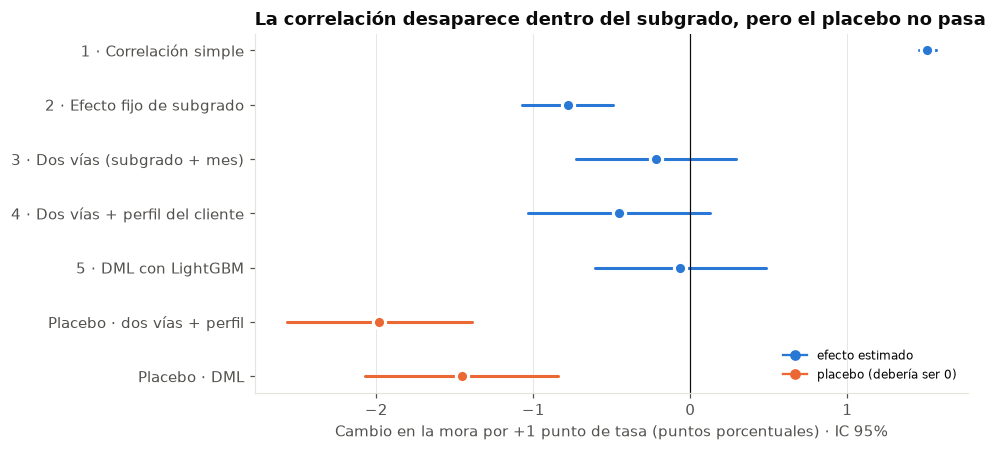

In [7]:
mora = pd.concat([
    fe.xs("malo", level=1).assign(tipo="efecto"),
    dml.xs("malo").loc[["DML · tasa de este mes"]].rename(index={"DML · tasa de este mes": "5 · DML con LightGBM"}).assign(tipo="efecto"),
    placebo.xs("malo").loc[["tasa_sig"]].rename(index={"tasa_sig": "Placebo · dos vías + perfil"}).assign(tipo="placebo"),
    dml.xs("malo").loc[["DML · placebo (mes siguiente)"]].rename(index={"DML · placebo (mes siguiente)": "Placebo · DML"}).assign(tipo="placebo"),
])
fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(mora))[::-1]
for (nombre, fila), y in zip(mora.iterrows(), yy):
    color = AZUL if fila["tipo"] == "efecto" else NARANJA
    ax.plot([fila["ic_bajo"] * 100, fila["ic_alto"] * 100], [y, y], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(fila["theta"] * 100, y, "o", color=color, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.axvline(0, color=TINTA, linewidth=0.8)
ax.set_yticks(yy, mora.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Cambio en la mora por +1 punto de tasa (puntos porcentuales) · IC 95%")
ax.plot([], [], "o-", color=AZUL, label="efecto estimado")
ax.plot([], [], "o-", color=NARANJA, label="placebo (debería ser 0)")
ax.legend(loc="lower right", frameon=False, fontsize=8)
ax.set_title("La correlación desaparece dentro del subgrado, pero el placebo no pasa")
fig.tight_layout()

**Lectura:** el DML da el mismo cuadro. El efecto contemporáneo en la mora es ≈ 0, pero el placebo vuelve a ser significativo. Controlar el perfil de forma flexible no basta: Lending Club reaccionaba a información que no está en los datos públicos. **Con estos datos el efecto causal de la tasa en la mora no queda identificado** (decisión 015).

## 5. Lo que sí se puede afirmar

1. **La correlación tasa–mora es selección.** Se borra al comparar dentro del subgrado, con cualquier método.
2. **Los efectos ≈ 0 no son prueba de que la tasa no afecte la mora.** El placebo dice que el diseño está contaminado.
3. **La pendiente de rendimiento del motor es conservadora.** El motor sube el ROI esperado menos de lo que estiman todos los métodos.

In [8]:
motor, motor_estres = Motor(), Motor(estres=True)
muestra_tr = tr.sample(5000, random_state=0)
cols = ["pd", "r_bueno", "r_malo", "roi_esperado"]
base = motor.evaluar(muestra_tr)[cols]
mas_uno = motor.evaluar(muestra_tr.assign(int_rate=muestra_tr["int_rate"] + 1))[cols]
pendiente = pd.Series({"Motor (supuesto: PD fija)": (mas_uno - base)["roi_esperado"].mean(),
                       "Dos vías": fe.loc[("3 · Dos vías (subgrado + mes)", "rendimiento"), "theta"],
                       "Dos vías + perfil": fe.loc[("4 · Dos vías + perfil del cliente", "rendimiento"), "theta"],
                       "DML": dml.loc[("rendimiento", "DML · tasa de este mes"), "theta"]})
pendiente.to_frame("ROI por +1 punto de tasa").style.format("{:+.2%}")

,ROI por +1 punto de tasa
Motor (supuesto: PD fija),+1.04%
Dos vías,+1.39%
Dos vías + perfil,+1.39%
DML,+1.28%


## 6. Integración al motor (decisión 015)

- **La PD sigue fija ante la tasa** en el escenario base.
- **Tasa de mercado:** la regresión de referencia recalibrada en nivel con ene–jun 2015 (Lending Club bajó sus tasas después de 2014), igual que la PD del campeón en la decisión 007.
- **Escenario de estrés:** la PD sube **+1 punto por cada punto** que la tasa supera la de mercado. Es la mayor estimación puntual del efecto de la tasa de este mes (+0,95 en dos vías + perfil, con el placebo incluido); los techos de los IC 95% sin placebo llegan a +0,5. Solo castiga el sobreprecio.
- **Bandera "fuera de rango":** la tasa se aleja más de 1 punto de la de mercado. Las tablas solo movieron la tasa ±0,74 puntos (p1–p99 del residuo de dos vías); más allá no hay evidencia.

### Backtest jul–dic 2015: ¿la PD del campeón se queda corta cuando Lending Club cobró más que el mercado?

Tasas de Lending Club fuera de rango (> ±1 pt): 69.9%


,préstamos,PD del campeón,mora real,ROI real
< −2,"41,599",16.0%,12.3%,6.3%
−2 a −1,"23,111",14.1%,12.4%,6.6%
−1 a +1 (en rango),"48,882",13.1%,13.1%,6.5%
+1 a +2,"17,527",13.6%,15.8%,6.5%
> +2,"31,117",15.4%,21.5%,5.0%


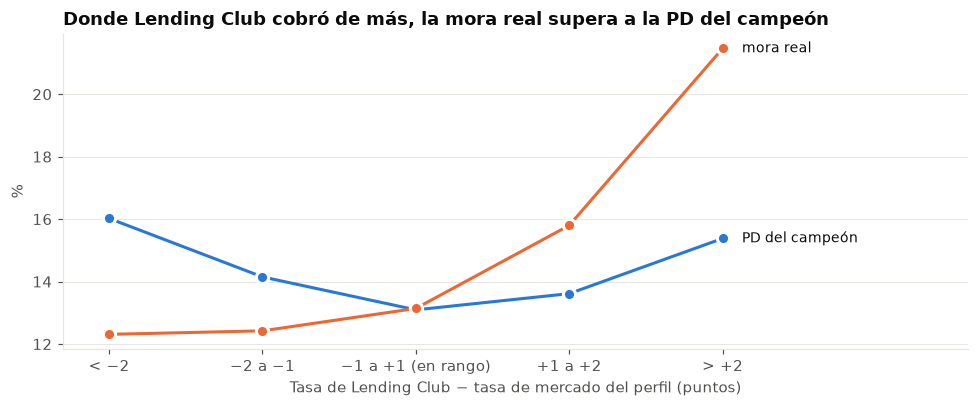

In [9]:
s2 = df[df["issue_d"] >= "2015-07-01"]
ev = motor.evaluar(s2)
sobreprecio = ev["tasa"] - ev["tasa_mercado"]
grupos = pd.cut(sobreprecio, [-np.inf, -2, -1, 1, 2, np.inf],
                labels=["< −2", "−2 a −1", "−1 a +1 (en rango)", "+1 a +2", "> +2"])
r2 = rendimiento(s2)
tabla_sp = pd.DataFrame({"préstamos": ev["pd"].groupby(grupos, observed=True).size(),
                         "PD del campeón": ev["pd"].groupby(grupos, observed=True).mean(),
                         "mora real": s2["malo"].groupby(grupos, observed=True).mean(),
                         "ROI real": (r2 * s2["funded_amnt"]).groupby(grupos, observed=True).sum() / s2["funded_amnt"].groupby(grupos, observed=True).sum()})

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(tabla_sp))
ax.plot(x, tabla_sp["PD del campeón"] * 100, "o-", color=AZUL, linewidth=2, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.plot(x, tabla_sp["mora real"] * 100, "o-", color=NARANJA, linewidth=2, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.text(x[-1] + 0.1, tabla_sp["PD del campeón"].iloc[-1] * 100, " PD del campeón", color=TINTA, va="center", fontsize=9)
ax.text(x[-1] + 0.1, tabla_sp["mora real"].iloc[-1] * 100, " mora real", color=TINTA, va="center", fontsize=9)
ax.set_xticks(x, tabla_sp.index)
ax.set_xlim(-0.3, len(x) + 0.6)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Tasa de Lending Club − tasa de mercado del perfil (puntos)")
ax.set_ylabel("%")
ax.set_title("Donde Lending Club cobró de más, la mora real supera a la PD del campeón")
fig.tight_layout()
print(f"Tasas de Lending Club fuera de rango (> ±1 pt): {ev['fuera_de_rango'].mean():.1%}")
tabla_sp.style.format({"préstamos": "{:,.0f}", "PD del campeón": "{:.1%}", "mora real": "{:.1%}", "ROI real": "{:.1%}"})

**Lectura:** el sobreprecio de Lending Club es **información**: sabían algo del cliente que nuestras variables no ven. No es evidencia de que la tasa cause la mora (eso es lo que el placebo no deja separar), pero sí una señal útil para el analista.

### Backtest del estrés sobre la tasa sugerida (10.000 préstamos de jul–dic 2015)

In [10]:
muestra = s2.sample(10_000, random_state=0)
t_base = tasa_minima_lote(motor, muestra, ROI_OBJETIVO)
t_estres = tasa_minima_lote(motor_estres, muestra, ROI_OBJETIVO)
ref = motor.tasa_mercado.predecir_recalibrada(muestra)
r, F, y = rendimiento(muestra).to_numpy(), muestra["funded_amnt"].to_numpy(), muestra["malo"].to_numpy()
roi_real = lambda m: (r * F)[m].sum() / F[m].sum()

sin_tasa = np.isnan(t_estres) & ~np.isnan(t_base)
sube = t_estres > t_base
resumen = pd.DataFrame({
    "préstamos": [len(muestra), sube.sum(), sin_tasa.sum()],
    "% de la muestra": [1, sube.mean(), sin_tasa.mean()],
    "ROI real": [roi_real(np.ones(len(muestra), bool)), roi_real(sube), roi_real(sin_tasa)],
    "mora real": [y.mean(), y[sube].mean(), y[sin_tasa].mean()],
}, index=["Todos", "El estrés sube la tasa sugerida", "Con estrés ninguna tasa llega al 4%"])
print(f"Tasa sugerida mediana: base {np.nanmedian(t_base):.1f}% · mercado {np.median(ref):.1f}%")
print(f"Tasa sugerida fuera de rango: {np.mean(np.abs(t_base - ref) > 1):.1%} (por debajo del mercado: {np.mean(t_base - ref < -1):.1%})")
resumen.style.format({"préstamos": "{:,.0f}", "% de la muestra": "{:.1%}", "ROI real": "{:.1%}", "mora real": "{:.1%}"})

Tasa sugerida mediana: base 7.5% · mercado 11.4%
Tasa sugerida fuera de rango: 85.5% (por debajo del mercado: 78.3%)


,préstamos,% de la muestra,ROI real,mora real
Todos,"10,000",100.0%,5.9%,14.5%
El estrés sube la tasa sugerida,391,3.9%,1.0%,27.4%
Con estrés ninguna tasa llega al 4%,485,4.9%,-1.3%,31.5%


---
## ✍️ Conclusiones de Neider

1. **La correlación no es causalidad.** Sin controles, +1 punto de tasa "trae" +1,5 puntos de mora; dentro del subgrado el efecto desaparece. Lending Club le cobra más a quien ya es más riesgoso.
2. **El experimento natural no pasó el placebo.** Ni con efectos fijos ni con DML: la tasa del mes siguiente predice la mora de hoy, porque Lending Club cambiaba sus tablas reaccionando a cómo se movía cada subgrado. El efecto causal de la tasa en la mora no queda identificado; reportarlo como ≈ 0 sería engañoso.
3. **El motor queda con la PD fija, un escenario de estrés y una bandera de fuera de rango.** La pendiente de rendimiento del motor (+1,0% de ROI por punto) es más conservadora que todas las estimaciones (+1,3% a +1,4%). Cuando Lending Club cobró más que el mercado, la mora real superó a la PD del campeón: es información que el analista debe ver. La tasa que maximiza el ROI no se puede calcular sin datos de aceptación.